# 07 · SV2A PET Imaging EDA
> *SV2A PET measures synaptic density — how many synapses survive in PD. A novel marker of neurodegeneration.*

## Background: What is SV2A PET?

**SV2A (Synaptic Vesicle Glycoprotein 2A)** is a protein present on nearly all synaptic vesicles (the packages that store neurotransmitters at synapses).

**Why measure it?** The number of synapses is closely correlated with neuronal health. As neurons die, their synapses disappear — SV2A provides a **direct measure of synaptic density**.

**Tracer used:** ¹⁸F-SynVesT-1 (also called [¹⁸F]UCB-H or ¹⁸F-SV2A ligand)

**Measurement — SUVR:**
- SV2A_SUVR_CS: SUVR normalised to **centrum semiovale** (white matter reference — no synapses)
- Other columns: SUVR for different brain regions

**Why it matters for PD:**
- Striatal synapse loss parallels dopamine neuron loss
- Cortical synapse loss may explain cognitive symptoms
- SV2A could serve as a marker of disease spread and severity

> ⚠️ **Small sample:** Only 18 participants, but 1,584 rows because multiple brain regions are measured per participant.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid', palette='colorblind')
plt.rcParams.update({'figure.figsize': (12, 5), 'axes.titlesize': 14,
                     'axes.labelsize': 12, 'xtick.labelsize': 10,
                     'ytick.labelsize': 10, 'figure.dpi': 120})
DATA_DIR = Path('../Imaging')
print(f'Data directory: {DATA_DIR.resolve()}')

Data directory: /Users/asadriaz/Desktop/PPMI Imaging/Imaging


In [2]:
VISIT_ORDER = ['SC', 'BL', 'V04', 'V06', 'V08', 'V10', 'V12', 'V14', 'V16', 'PW']
VISIT_LABELS = {'SC': 'Screening', 'BL': 'Baseline', 'PW': 'Withdrawal',
                'V04': 'Yr 1', 'V06': 'Yr 2', 'V08': 'Yr 3',
                'V10': 'Yr 4', 'V12': 'Yr 5', 'V14': 'Yr 6', 'V16': 'Yr 7'}
def ordered_visits(series):
    present = series.dropna().unique().tolist()
    ordered = [v for v in VISIT_ORDER if v in present]
    return ordered + sorted([v for v in present if v not in VISIT_ORDER])

## Load Data Files

In [3]:
sv2a_sub  = pd.read_csv(DATA_DIR / 'SV2A_PET_Imaging_Substudy_SV2A_PET_Imaging_12Nov2026.csv')
sv2a_meta = pd.read_csv(DATA_DIR / 'SV2A_PET_Acquisition_Metadata_12Nov2026.csv')
sv2a_suvr = pd.read_csv(DATA_DIR / 'SV2A_PET_SUVR_Analysis_12Nov2026.csv')
for name, df in [('SV2A Substudy', sv2a_sub), ('SV2A Metadata', sv2a_meta), ('SV2A SUVR', sv2a_suvr)]:
    print(f'{name:25s}: {len(df):>5,} rows | {df["PATNO"].nunique()} participants | {df.shape[1]} cols')
print()
print('SUVR file columns:', sv2a_suvr.columns.tolist())

SV2A Substudy            :    18 rows | 15 participants | 20 cols
SV2A Metadata            :    18 rows | 15 participants | 17 cols
SV2A SUVR                : 1,584 rows | 15 participants | 9 cols

SUVR file columns: ['PROTOCOL', 'PATNO', 'EVENT_ID', 'SV2A_SCAN_DATE', 'SV2A_REGION', 'SV2A_SUVR_CS', 'SV2A_ANALYZED', 'SV2A_NOT_ANALYZED_REASON', 'SV2A_OTHER_SPECIFY']


## Column Reference

### SV2A Acquisition Metadata
| Column | Meaning |
|--------|---------|
| `PET_LIGAND` | Tracer: [18F]SynVesT-1 |
| `PET_TOTAL_DOSE_CALC` | Injected dose |
| `PET_IMAGE_ACCEPTABLE` | QC pass: Yes/No |
| `PET_SCANNER` | Scanner model |

### SV2A SUVR Analysis
| Column | Meaning |
|--------|---------|
| `SV2A_SUVR_CS` | SUVR in centrum semiovale (white matter — reference region, expected ~1.0) |
| Region columns | SUVR in various cortical and subcortical regions |

**Region abbreviations** in column names:
- `FL_` = Frontal Lobe
- `TL_` = Temporal Lobe
- `PL_` = Parietal Lobe
- `OL_` = Occipital Lobe
- `_L` / `_R` = Left / Right

## 1 · Data Structure Overview

In [4]:
print(f'Participants: {sv2a_suvr["PATNO"].nunique()}')
print(f'Total rows: {len(sv2a_suvr):,}')
print(f'Rows per participant: {len(sv2a_suvr)/sv2a_suvr["PATNO"].nunique():.0f}')
suvr_cols = [c for c in sv2a_suvr.columns
             if sv2a_suvr[c].dtype in [np.float64, float] and c != 'PATNO']
print(f'Numeric SUVR columns: {len(suvr_cols)}')
print('\nFirst few columns:', suvr_cols[:8])

Participants: 15
Total rows: 1,584
Rows per participant: 106
Numeric SUVR columns: 2

First few columns: ['SV2A_SUVR_CS', 'SV2A_OTHER_SPECIFY']


## 2 · SUVR Distribution Across All Regions

Values > 1.0 mean more tracer (more synapses) than white matter reference.

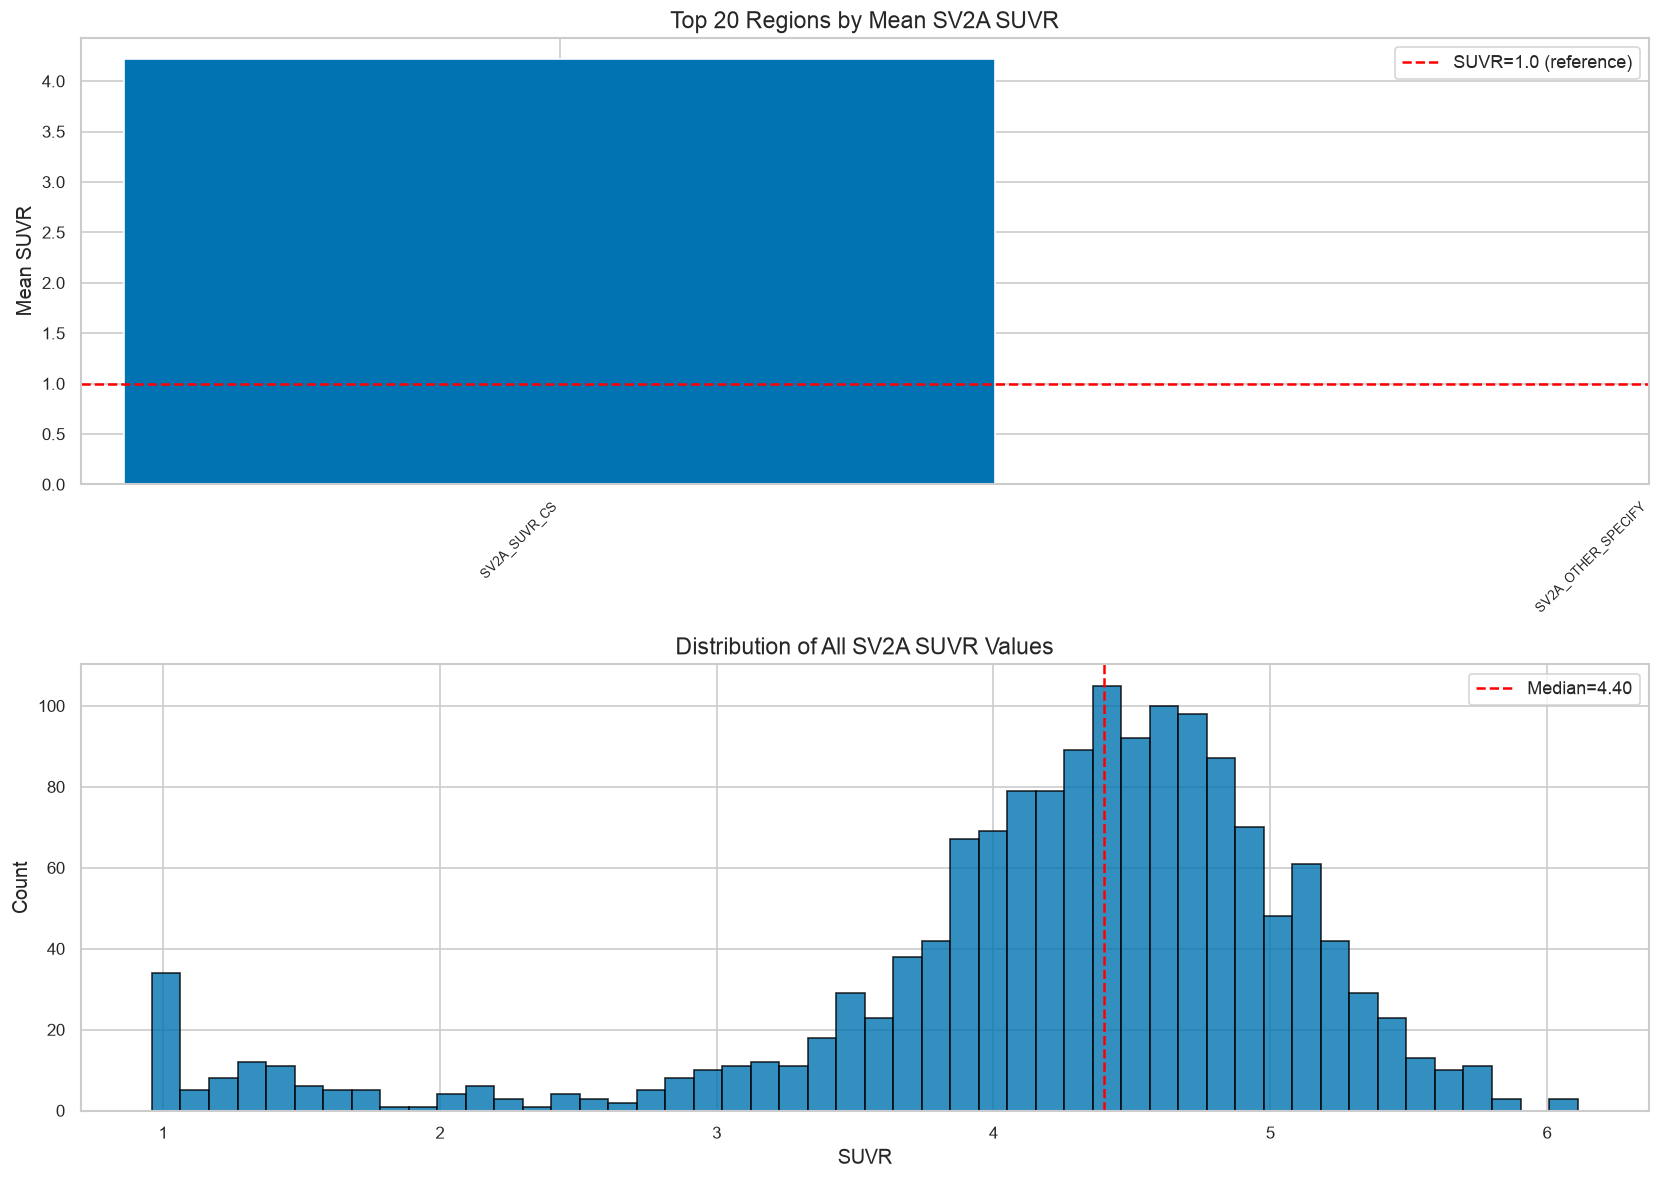

In [5]:
if suvr_cols:
    means = sv2a_suvr[suvr_cols].mean().sort_values(ascending=False)
    stds  = sv2a_suvr[suvr_cols].std()

    fig, axes = plt.subplots(2, 1, figsize=(14, 10))
    # Mean SUVR bar chart
    top = means.head(20)
    axes[0].bar(range(len(top)), top.values,
                color=sns.color_palette('colorblind', min(len(top), 10))*3,
                edgecolor='white')
    axes[0].set_xticks(range(len(top)))
    axes[0].set_xticklabels(top.index, rotation=45, ha='right', fontsize=8)
    axes[0].axhline(1.0, color='red', linestyle='--', label='SUVR=1.0 (reference)')
    axes[0].set_title('Top 20 Regions by Mean SV2A SUVR'); axes[0].legend()
    axes[0].set_ylabel('Mean SUVR')

    # Distribution of all SUVR values
    all_vals = sv2a_suvr[suvr_cols].values.flatten()
    all_vals = all_vals[~np.isnan(all_vals)]
    axes[1].hist(all_vals, bins=50, color=sns.color_palette('colorblind')[0],
                 edgecolor='black', alpha=0.8)
    axes[1].axvline(np.median(all_vals), color='red', linestyle='--',
                    label=f'Median={np.median(all_vals):.2f}')
    axes[1].set_title('Distribution of All SV2A SUVR Values')
    axes[1].set_xlabel('SUVR'); axes[1].set_ylabel('Count'); axes[1].legend()
    plt.tight_layout(); plt.show()

## 3 · Left vs Right Regional Symmetry

Are matching left and right regions symmetric in SV2A signal?

In [6]:
# Find left-right pairs by naming convention
l_cols = [c for c in suvr_cols if c.endswith('_L') and c[:-2]+'_R' in suvr_cols]
r_cols = [c[:-2]+'_R' for c in l_cols]

if l_cols:
    n_pairs = min(len(l_cols), 6)
    fig, axes = plt.subplots(2, 3, figsize=(14, 8))
    axes = axes.flatten()
    for i, (lc, rc) in enumerate(zip(l_cols[:n_pairs], r_cols[:n_pairs])):
        sub = sv2a_suvr[[lc, rc]].dropna()
        if len(sub) < 2: continue
        mn = sub.min().min()*0.9; mx = sub.max().max()*1.05
        axes[i].scatter(sub[lc], sub[rc], alpha=0.6, s=30,
                        color=sns.color_palette('colorblind')[i%6])
        axes[i].plot([mn,mx],[mn,mx],'r--', alpha=0.7)
        region = lc.replace('_L','').replace('SV2A_SUVR_','')
        axes[i].set_xlabel(f'{region} Left'); axes[i].set_ylabel(f'{region} Right')
        axes[i].set_title(region, fontsize=9)
    plt.suptitle('SV2A SUVR: Left vs Right Hemisphere', fontsize=13)
    plt.tight_layout(); plt.show()

## 4 · Acquisition Metadata

In [7]:
print('Acquisition summary:')
print(f'  Participants: {sv2a_meta["PATNO"].nunique()}')
for col in sv2a_meta.columns:
    vc = sv2a_meta[col].value_counts()
    if 1 < len(vc) <= 8 and col not in ['PATNO','EVENT_ID']:
        print(f'\n{col}:'); print(vc.to_string())
num_meta = sv2a_meta.select_dtypes(include='number').columns.difference(['PATNO'])
if len(num_meta) > 0:
    print('\nNumeric metadata summary:')
    print(sv2a_meta[num_meta].describe().round(2))

Acquisition summary:
  Participants: 15

SV2A_SCAN_QUALITY_RATING:
SV2A_SCAN_QUALITY_RATING
2    13
1     4
3     1

Numeric metadata summary:
       PROTOCOL  SCANNER_CHANGE_AFTER_PREVIOUS  SV2A_INJECTION_VOLUME  \
count      18.0                            0.0                  18.00   
mean       14.0                            NaN                   3.26   
std         0.0                            NaN                   1.21   
min        14.0                            NaN                   1.63   
25%        14.0                            NaN                   2.52   
50%        14.0                            NaN                   2.96   
75%        14.0                            NaN                   3.98   
max        14.0                            NaN                   5.91   

       SV2A_SCAN_QUALITY_RATING  SV2A_TOTAL_DOSE_CALC  SV2A_WEIGHT  
count                     18.00                 18.00        18.00  
mean                       1.83                226.96        

## Key Takeaways

- **SV2A measures synaptic density** — a marker of neurodegeneration independent of dopamine
- **Only 18 participants** in this pilot substudy — findings are exploratory
- **SUVR > 1.0 everywhere** because cortical grey matter is synapse-rich (much more than white matter)
- **High left-right symmetry** at the group level
- **Striatal and cortical SV2A** are the most PD-relevant targets — reduced in areas with neuronal loss
- **SV2A may detect neurodegeneration earlier than volumetry** — synapses are lost before neurons die